# Audio Pipeline and Voice Verification Model (IMANZI Yannick Kenny)

This notebook covers the audio track: loading and trimming recordings, waveform and spectrogram visualization, augmentation, feature extraction (`audio_features.csv`), training and evaluating the voice model, and the `verify_voice` function used by the command-line app.

## Cell 1: Setup and imports

Mounts Google Drive, imports the libraries (librosa, pandas, matplotlib, etc.), sets the audio folder path and the global settings (sampling rate 16 kHz, trimming threshold 20 dB), and checks that the folder exists.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob, re
import numpy as np
import pandas as pd
import librosa, librosa.display
import matplotlib.pyplot as plt

AUDIO_DIR = "/content/drive/MyDrive/formative2_audio"
SR = 16000
TOP_DB = 20

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Cell 2: Find audio files and parse member, phrase and take

Scans the Drive folder for `.wav` files and reads the member name, phrase and take number from each file name. Files with names that do not match the pattern are listed as skipped. The output table shows how many recordings each member has per phrase.

In [2]:
pattern = re.compile(
    r"^(?P<member>[a-z]+)_(?P<phrase>yes_approve|confirm_transaction)(?:_(?P<take>\d+))?\.wav$"
)

records, skipped = [], []
for path in sorted(glob.glob(os.path.join(AUDIO_DIR, "*.wav"))):
    m = pattern.match(os.path.basename(path).lower())
    if m:
        records.append({"path": path, "member": m["member"],
                        "phrase": m["phrase"], "take": m["take"] or "01"})
    else:
        skipped.append(os.path.basename(path))

files_df = pd.DataFrame(records)
print("Files found:", len(files_df))
print("Skipped (bad names):", skipped)
files_df.groupby(["member", "phrase"]).size().unstack(fill_value=0)

Files found: 24
Skipped (bad names): []


phrase,confirm_transaction,yes_approve
member,,
aurele,3,3
frank,3,3
kenny,3,3
unauthorized,3,3


## Cell 3a: Load and trim every clip

Loads each recording with `librosa.load` at 16 kHz, then removes silence at the start and end with `librosa.effects.trim` (top_db=20, as in class). The waveform arrays (`y`, `y_trim`) and the durations before and after trimming are stored in `audio_df`.

In [3]:
rows = []
for r in records:
    y, sr = librosa.load(r["path"], sr=SR)
    y_trim, _ = librosa.effects.trim(y, top_db=TOP_DB)
    rows.append({**r, "y": y, "y_trim": y_trim, "sr": sr,
                 "dur_raw": len(y) / sr, "dur_trim": len(y_trim) / sr})

audio_df = pd.DataFrame(rows)
audio_df[["member", "phrase", "take", "sr", "dur_raw", "dur_trim"]].round(2)

,member,phrase,take,sr,dur_raw,dur_trim
0,aurele,confirm_transaction,01,16000,3.91,1.22
1,aurele,confirm_transaction,02,16000,3.57,1.34
2,aurele,confirm_transaction,03,16000,3.93,1.31
3,aurele,yes_approve,01,16000,4.07,1.15
4,aurele,yes_approve,02,16000,3.41,1.18
5,aurele,yes_approve,03,16000,3.47,1.18
6,frank,confirm_transaction,01,16000,4.71,1.76
7,frank,confirm_transaction,02,16000,2.45,1.31
8,frank,confirm_transaction,03,16000,2.05,1.02
9,frank,yes_approve,01,16000,4.25,1.57


## Cell 3b: Visual check of trimming on one clip

Plots the first clip in `audio_df` before and after trimming (amplitude versus time, as in class). The raw waveform should show silence at the start and end, and the trimmed waveform should begin and end at the speech.

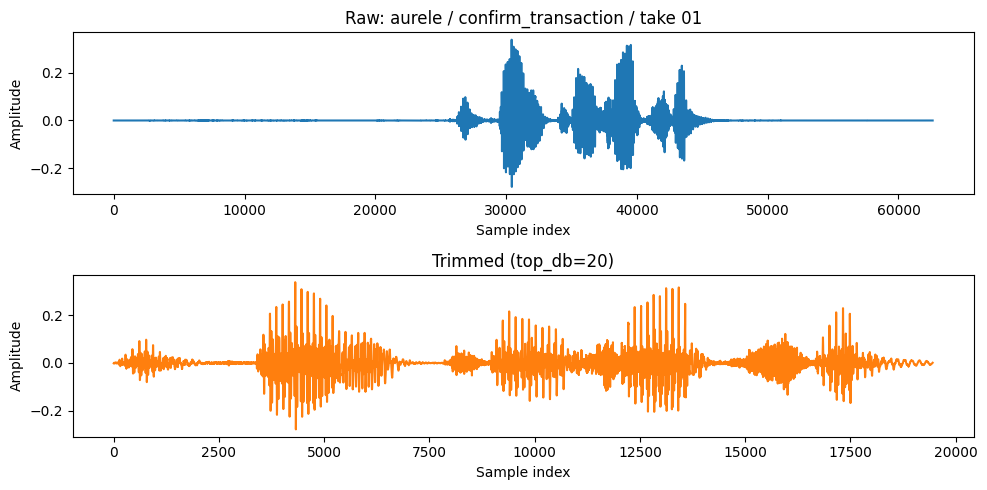

In [4]:
r = audio_df.iloc[0]

fig, ax = plt.subplots(2, 1, figsize=(10, 5))

ax[0].plot(r["y"])
ax[0].set_title(f"Raw: {r['member']} / {r['phrase']} / take {r['take']}")
ax[0].set_xlabel("Sample index")
ax[0].set_ylabel("Amplitude")

ax[1].plot(r["y_trim"], color="tab:orange")
ax[1].set_title("Trimmed (top_db=20)")
ax[1].set_xlabel("Sample index")
ax[1].set_ylabel("Amplitude")

plt.tight_layout()
plt.show()

**Interpretation:** the raw clip contains seconds of near-silence before and after the phrase. After `librosa.effects.trim` only the spoken part remains, so the features extracted later describe the voice rather than the pauses.

## Cell 4: Waveform and spectrogram for every member

For each member, plots one take of each phrase: the trimmed waveform (amplitude versus time) next to its spectrogram (frequency versus time in dB), computed with `librosa.stft` and `amplitude_to_db` as in the class slides. The unauthorized recordings are skipped here.

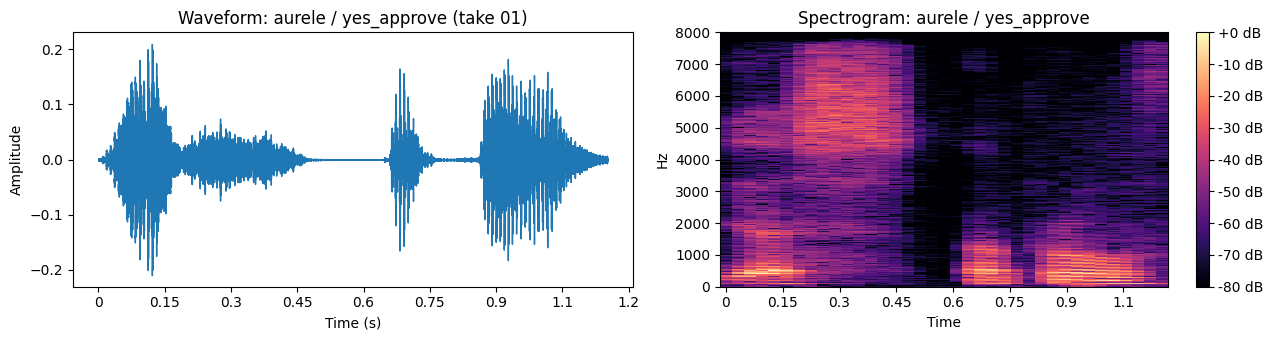

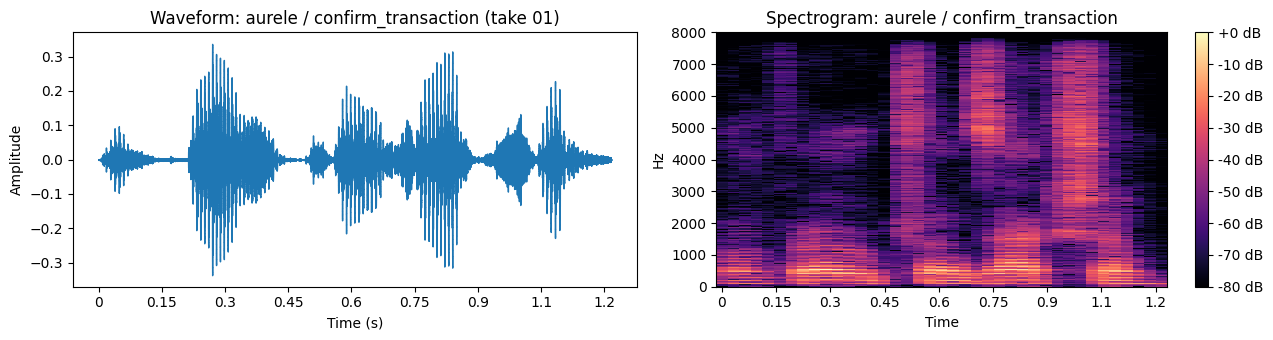

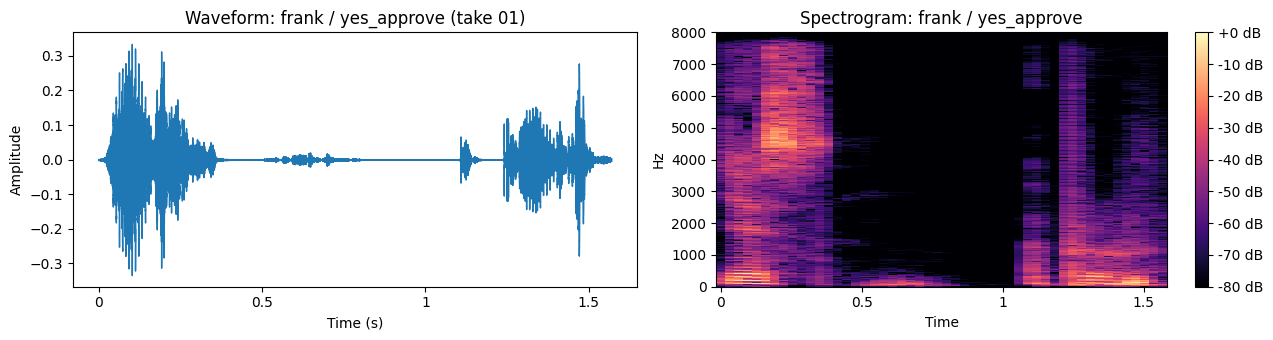

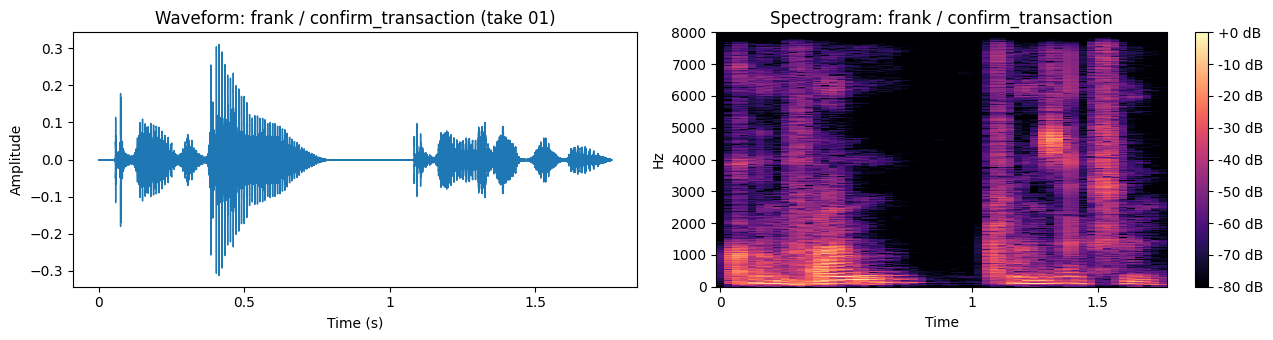

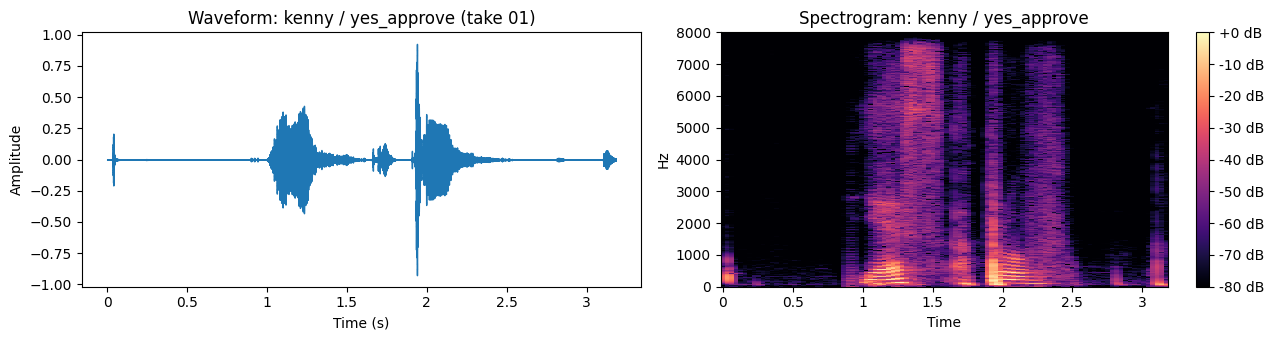

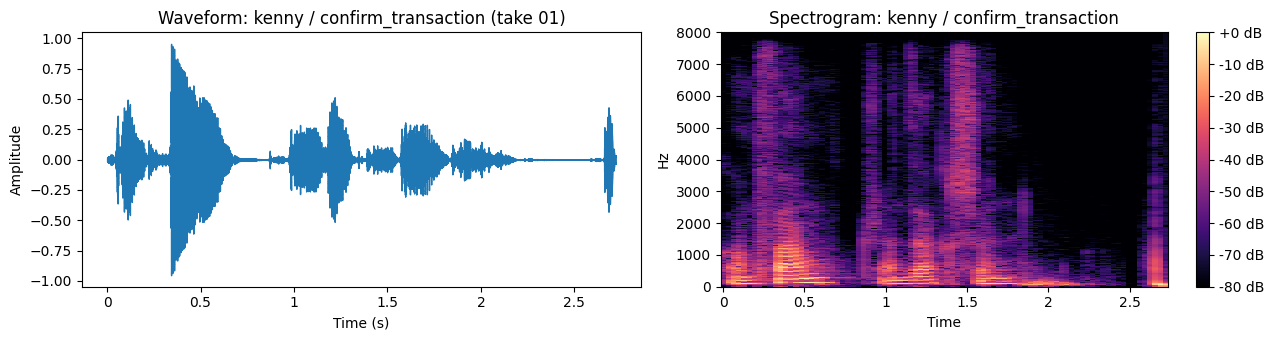

In [5]:
members = sorted(m for m in audio_df["member"].unique() if m != "unauthorized")
phrases = ["yes_approve", "confirm_transaction"]

for member in members:
    for phrase in phrases:
        sub = audio_df[(audio_df["member"] == member) & (audio_df["phrase"] == phrase)]
        if sub.empty:
            print(f"Missing: {member} / {phrase}")
            continue

        r = sub.iloc[0]          # first take
        y, sr = r["y_trim"], r["sr"]

        fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))

        # Waveform: amplitude vs time
        librosa.display.waveshow(y, sr=sr, ax=ax[0], color="tab:blue")
        ax[0].set_title(f"Waveform: {member} / {phrase} (take {r['take']})")
        ax[0].set_xlabel("Time (s)")
        ax[0].set_ylabel("Amplitude")

        # Spectrogram: STFT -> dB
        D = librosa.stft(y)
        S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)
        img = librosa.display.specshow(S_db, sr=sr, x_axis="time", y_axis="hz", ax=ax[1])
        ax[1].set_title(f"Spectrogram: {member} / {phrase}")
        fig.colorbar(img, ax=ax[1], format="%+2.0f dB")

        plt.tight_layout()
        plt.show()

**Interpretation of waveforms and spectrograms:** each phrase appears in the waveform as a few bursts of energy, one per word or syllable group, separated by short pauses. The spectrograms show which frequencies are present and how they change over time. The members differ in loudness, timing and band spacing, which is why spectral features can separate speakers.

**Recording-quality note:** the duration table in Cell 3a shows that Aurele's and Frank's clips shrink to about 1 to 1.8 s after trimming, while Kenny's and the unauthorized speaker's clips stay at about 2.7 to 4.3 s. Kenny's waveform has short clicks at the start and end and a loud transient (amplitude close to 1.0), which `trim` treats as sound, so about a second of silence stays inside the clip. This is a limitation: the model may partly learn recording conditions and not only the voice.

## Cell 5: Audio augmentations (noise, pitch shift, time stretch)

Applies three augmentations to every trimmed clip: random noise (as in the class breakout task), pitch shift (+2 semitones) and time stretch (rate 1.1). The `take` number is kept on every augmented copy, so train and test can be split by original recording later (this avoids data leakage). Augmented clips are also saved as `.wav` files.

In [6]:
import soundfile as sf

AUG_DIR = "/content/drive/MyDrive/formative2_audio_aug"
os.makedirs(AUG_DIR, exist_ok=True)

rng = np.random.default_rng(42)   # fixed seed so results are reproducible

def add_noise(y, noise_level=0.005):
    return y + noise_level * rng.standard_normal(len(y))

def pitch_shift(y, sr, n_steps=2):
    return librosa.effects.pitch_shift(y, sr=sr, n_steps=n_steps)

def time_stretch(y, rate=1.1):
    return librosa.effects.time_stretch(y, rate=rate)

augmentations = {
    "noise":   lambda y, sr: add_noise(y),
    "pitch":   lambda y, sr: pitch_shift(y, sr),
    "stretch": lambda y, sr: time_stretch(y),
}

rows = []
for _, r in audio_df.iterrows():
    # keep the original clip as one row
    rows.append({"member": r["member"], "phrase": r["phrase"], "take": r["take"],
                 "augmentation": "original", "y": r["y_trim"], "sr": r["sr"]})

    # add one row per augmentation
    for name, fn in augmentations.items():
        y_aug = fn(r["y_trim"], r["sr"]).astype(np.float32)
        rows.append({"member": r["member"], "phrase": r["phrase"], "take": r["take"],
                     "augmentation": name, "y": y_aug, "sr": r["sr"]})
        fname = f"{r['member']}_{r['phrase']}_{r['take']}_{name}.wav"
        sf.write(os.path.join(AUG_DIR, fname), y_aug, r["sr"])

aug_df = pd.DataFrame(rows)
print("Total clips (original + augmented):", len(aug_df))
aug_df.groupby(["member", "augmentation"]).size().unstack(fill_value=0)

Total clips (original + augmented): 96


augmentation,noise,original,pitch,stretch
member,,,,
aurele,6,6,6,6
frank,6,6,6,6
kenny,6,6,6,6
unauthorized,6,6,6,6


**Interpretation:** noise simulates a noisier room, pitch shift simulates a slightly higher voice and time stretch simulates a faster speaker. These variations make the model less sensitive to recording conditions. The dataset grows from 24 to 96 clips (original plus 3 augmentations). Augmented clips are used only for training, never for testing.

## Cell 6: Feature extraction and saving audio_features.csv

Computes features for every clip (original and augmented): 13 MFCCs (mean over time), spectral roll-off, RMS energy and zero-crossing rate. One row per clip is saved to `audio_features.csv` with the columns member, phrase, take, augmentation and the 16 feature values.

In [7]:
def extract_features(y, sr):
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    feats = {f"mfcc_{i+1}": mfcc[i].mean() for i in range(13)}
    feats["rolloff"] = librosa.feature.spectral_rolloff(y=y, sr=sr).mean()
    feats["energy"] = librosa.feature.rms(y=y).mean()
    feats["zcr"] = librosa.feature.zero_crossing_rate(y).mean()
    return feats

feature_rows = []
for _, r in aug_df.iterrows():
    f = extract_features(r["y"], r["sr"])
    feature_rows.append({"member": r["member"], "phrase": r["phrase"],
                         "take": r["take"], "augmentation": r["augmentation"], **f})

features_df = pd.DataFrame(feature_rows)

OUT_PATH = "/content/drive/MyDrive/audio_features.csv"
features_df.to_csv(OUT_PATH, index=False)

print("Shape:", features_df.shape)
print("Missing values:", features_df.isna().sum().sum())
features_df.head()

Shape: (96, 20)
Missing values: 0


,member,phrase,take,augmentation,mfcc_1,mfcc_2,mfcc_3,mfcc_4,mfcc_5,mfcc_6,mfcc_7,mfcc_8,mfcc_9,mfcc_10,mfcc_11,mfcc_12,mfcc_13,rolloff,energy,zcr
0,aurele,confirm_transaction,01,original,-311.698761,109.465385,28.588501,0.440611,-9.040578,0.133680,-37.357666,-1.020573,-10.473712,0.915245,-4.138987,-3.675381,4.835129,2796.274038,0.041826,0.157089
1,aurele,confirm_transaction,01,noise,-221.843430,53.449333,28.090679,4.403499,-4.740873,-8.477027,-19.678579,-9.055959,-6.731988,1.985787,-1.829482,-0.787495,2.477742,5108.573718,0.042272,0.233073
2,aurele,confirm_transaction,01,pitch,-313.595215,107.243637,26.982243,-15.269900,-7.750490,-17.222387,-34.178513,4.069027,-10.340920,7.058279,-9.027495,6.555110,-5.381946,3299.679487,0.030679,0.164939
3,aurele,confirm_transaction,01,stretch,-305.687073,107.301491,32.231102,-4.527324,-10.685534,-1.626931,-41.091675,-2.577478,-11.782500,3.968933,-6.256510,-1.847257,4.688961,3341.517857,0.031161,0.152455
4,aurele,confirm_transaction,02,original,-324.454498,122.112961,14.514600,-6.644202,0.798077,2.573897,-35.409912,-0.156133,-11.505766,-0.806935,-3.531137,-3.031817,1.126601,2799.600291,0.041090,0.150107


**Interpretation:** each clip is now described by 16 numbers: 13 MFCCs, roll-off, energy and zero-crossing rate. MFCCs summarize the shape of the mel spectrogram, which depends on the speaker's vocal tract, while roll-off and energy describe brightness and loudness. The file has 96 rows and no missing values.

## Cell 7: Train/test split by original recording and train the voice model

Splits by `take`, not by row: takes 01 and 02 (original and augmented copies) are used for training, and take 03 (originals only) is held out for testing, so no augmented copy of a test clip appears in training. The `unauthorized` speaker is excluded. Features are scaled with `StandardScaler`, then Logistic Regression and Random Forest are trained to identify the speaker and evaluated with accuracy, macro F1 and log loss.

In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss, confusion_matrix

FEATURES = [c for c in features_df.columns
            if c not in ["member", "phrase", "take", "augmentation"]]

# Exclude the unauthorized speaker from training and testing
data = features_df[features_df["member"] != "unauthorized"]

TEST_TAKE = "03"
train = data[data["take"] != TEST_TAKE]                                   # originals + augmented
test  = data[(data["take"] == TEST_TAKE) & (data["augmentation"] == "original")]


key = lambda d: set(zip(d["member"], d["phrase"], d["take"]))
assert key(train).isdisjoint(key(test)), "Leakage: same recording in train and test!"

X_train, y_train = train[FEATURES], train["member"]
X_test,  y_test  = test[FEATURES],  test["member"]
print("Train clips:", len(train), "| Test clips:", len(test))
print("Speakers:", sorted(y_train.unique()))

models = {
    "Logistic Regression": make_pipeline(StandardScaler(),
                                         LogisticRegression(max_iter=2000)),
    "Random Forest": make_pipeline(StandardScaler(),
                                   RandomForestClassifier(n_estimators=200, random_state=42)),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred  = model.predict(X_test)
    proba = model.predict_proba(X_test)
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "f1_macro": f1_score(y_test, pred, average="macro"),
        "log_loss": log_loss(y_test, proba, labels=model.classes_),
    })
    print(f"\n{name}: confusion matrix (rows = true, columns = predicted)")
    print(pd.DataFrame(confusion_matrix(y_test, pred, labels=model.classes_),
                       index=model.classes_, columns=model.classes_))

pd.DataFrame(results).round(3)

Train clips: 48 | Test clips: 6
Speakers: ['aurele', 'frank', 'kenny']

Logistic Regression: confusion matrix (rows = true, columns = predicted)
        aurele  frank  kenny
aurele       2      0      0
frank        0      2      0
kenny        0      0      2

Random Forest: confusion matrix (rows = true, columns = predicted)
        aurele  frank  kenny
aurele       2      0      0
frank        0      2      0
kenny        0      0      2


,model,accuracy,f1_macro,log_loss
0,Logistic Regression,1.0,1.0,0.026
1,Random Forest,1.0,1.0,0.151


**Interpretation:** the split is done by recording (take), so no augmented copy of a test clip is in training (the leakage assertion passes). Both models identify all 6 test clips correctly (accuracy 1.0, macro F1 1.0), and Logistic Regression has the lower log loss (0.026 against 0.151), so its probabilities are better calibrated. With only 6 test clips and 3 speakers these metrics are indicative and should not be read as proof of generalization.

## Cell 8: Baseline model: best model with a confidence threshold

Picks the better model from Cell 7 (highest macro F1, then lowest log loss). The model gives a probability per member and the highest one is its confidence. A voice is accepted only if the confidence reaches a threshold chosen from the gap between the authorized test clips and the unauthorized recordings. This baseline is saved as `voice_model.joblib` and tested in Cells 9b to 9d. It is later replaced by the final model in Cell 9f.

In [9]:
import joblib

# 1. Pick the best model from Cell 7
results_df = pd.DataFrame(results)
best_name = (results_df.sort_values(["f1_macro", "log_loss"], ascending=[False, True])
                       .iloc[0]["model"])
best = models[best_name]
print("Best model:", best_name)

# 2. Confidence = highest predicted probability
auth_conf = best.predict_proba(X_test).max(axis=1)

unauth = features_df[(features_df["member"] == "unauthorized") &
                     (features_df["augmentation"] == "original")]
if unauth.empty:
    print("WARNING: no unauthorized recording found, using default threshold 0.60")
    unauth_conf = np.array([])
else:
    unauth_conf = best.predict_proba(unauth[FEATURES]).max(axis=1)

print("Authorized test confidence:   min %.2f, mean %.2f" % (auth_conf.min(), auth_conf.mean()))
if len(unauth_conf):
    print("Unauthorized confidence:      max %.2f" % unauth_conf.max())

# 3. Choose the threshold
if len(unauth_conf) and auth_conf.min() > unauth_conf.max():
    THRESHOLD = round((auth_conf.min() + unauth_conf.max()) / 2, 2)   # midpoint of the gap
else:
    THRESHOLD = 0.60
print("THRESHOLD =", THRESHOLD)

# 4. How each threshold behaves
rows = []
for t in [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]:
    rows.append({"threshold": t,
                 "authorized accepted": f"{(auth_conf >= t).mean():.0%}",
                 "unauthorized rejected": f"{(unauth_conf < t).mean():.0%}" if len(unauth_conf) else "n/a"})
display(pd.DataFrame(rows))

# 5. Save the SAME model the threshold was calibrated on
bundle = {"model": best, "features": FEATURES, "threshold": THRESHOLD,
          "sr": SR, "top_db": TOP_DB, "classes": list(best.classes_)}
joblib.dump(bundle, "/content/drive/MyDrive/voice_model.joblib")
print("Saved voice_model.joblib | speakers:", bundle["classes"])

Best model: Logistic Regression
Authorized test confidence:   min 0.93, mean 0.97
Unauthorized confidence:      max 0.91
THRESHOLD = 0.92


,threshold,authorized accepted,unauthorized rejected
0,0.40,100%,0%
1,0.50,100%,0%
2,0.60,100%,0%
3,0.70,100%,0%
4,0.80,100%,33%
5,0.90,100%,83%
6,0.95,83%,100%


Saved voice_model.joblib | speakers: ['aurele', 'frank', 'kenny']


**Interpretation:** the weakest authorized test clip has confidence 0.93 and the strongest unauthorized clip 0.91, so the threshold is set in between at 0.92. The margin is narrow (about 0.02 on each side). The table shows the trade-off: at 0.90 one stranger clip is accepted, and at 0.95 one real member clip is rejected. The threshold was tuned on the same unauthorized clips, and they come from a single speaker, so a perfect result in the next cell is expected and is not an independent test.

## Cell 9a: verify_voice(audio_path) for the command-line app

Loads the saved bundle (`voice_model.joblib`) and repeats the training steps: load at 16 kHz, trim silence, extract the same features in the same order. A voice is approved only if the predicted class is a member (not the "unauthorized" class, when the bundle has one) and the confidence reaches the saved threshold. Returns `(is_approved, predicted_member, confidence)`. Cells 9b to 9d run it on the baseline model saved in Cell 8.

In [10]:
import joblib

BUNDLE_PATH = "/content/drive/MyDrive/voice_model.joblib"

def verify_voice(audio_path, bundle_path=BUNDLE_PATH):
    """Returns (is_approved, predicted_member, confidence)."""
    bundle = joblib.load(bundle_path)

    y, sr = librosa.load(audio_path, sr=bundle["sr"])
    y, _ = librosa.effects.trim(y, top_db=bundle["top_db"])
    if len(y) < 0.2 * sr:
        return False, None, 0.0

    X = pd.DataFrame([extract_features(y, sr)])[bundle["features"]]
    proba = bundle["model"].predict_proba(X)[0]
    i = int(np.argmax(proba))
    member, confidence = bundle["classes"][i], float(proba[i])

    # Reject if the model says "unauthorized" or the confidence is below the floor
    ok = (member != bundle.get("reject_class")) and (confidence >= bundle["threshold"])
    return bool(ok), (member if ok else None), confidence

## Cell 9b: Test verify_voice on authorized and unauthorized recordings

Runs `verify_voice` on every unauthorized recording (all takes, both phrases), which should all be rejected, and on one authorized clip per member, which should be approved.

In [11]:
print("--- Unauthorized (all should be rejected) ---")
for p in sorted(glob.glob(os.path.join(AUDIO_DIR, "unauthorized_*.wav"))):
    ok, who, conf = verify_voice(p)
    print(f"{os.path.basename(p):45s} approved={bool(ok)!s:5s} member={who} confidence={conf:.2f}")

print("\n--- Authorized (all should be approved) ---")
for m in members:
    p = os.path.join(AUDIO_DIR, f"{m}_confirm_transaction_03.wav")
    if os.path.exists(p):
        ok, who, conf = verify_voice(p)
        print(f"{os.path.basename(p):45s} approved={bool(ok)!s:5s} member={who} confidence={conf:.2f}")

--- Unauthorized (all should be rejected) ---
unauthorized_confirm_transaction_01.wav       approved=False member=None confidence=0.81
unauthorized_confirm_transaction_02.wav       approved=False member=None confidence=0.80
unauthorized_confirm_transaction_03.wav       approved=False member=None confidence=0.71
unauthorized_yes_approve_01.wav               approved=False member=None confidence=0.91
unauthorized_yes_approve_02.wav               approved=False member=None confidence=0.84
unauthorized_yes_approve_03.wav               approved=False member=None confidence=0.72

--- Authorized (all should be approved) ---
aurele_confirm_transaction_03.wav             approved=True  member=aurele confidence=0.96
frank_confirm_transaction_03.wav              approved=True  member=frank confidence=0.99
kenny_confirm_transaction_03.wav              approved=True  member=kenny confidence=0.98


## Cell 9c: Probability per member for each unauthorized clip

Prints the saved threshold and the probability the model gives to each member for every unauthorized recording, to see how close the stranger's voice is to the members.

In [12]:
bundle = joblib.load(BUNDLE_PATH)
print("Saved threshold:", bundle["threshold"])

for p in sorted(glob.glob(os.path.join(AUDIO_DIR, "unauthorized_*.wav"))):
    y, sr = librosa.load(p, sr=bundle["sr"])
    y, _ = librosa.effects.trim(y, top_db=bundle["top_db"])
    X = pd.DataFrame([extract_features(y, sr)])[bundle["features"]]
    proba = bundle["model"].predict_proba(X)[0]
    print(os.path.basename(p), dict(zip(bundle["classes"], proba.round(2))))

Saved threshold: 0.92
unauthorized_confirm_transaction_01.wav {'aurele': np.float64(0.17), 'frank': np.float64(0.02), 'kenny': np.float64(0.81)}
unauthorized_confirm_transaction_02.wav {'aurele': np.float64(0.16), 'frank': np.float64(0.03), 'kenny': np.float64(0.8)}
unauthorized_confirm_transaction_03.wav {'aurele': np.float64(0.71), 'frank': np.float64(0.11), 'kenny': np.float64(0.18)}
unauthorized_yes_approve_01.wav {'aurele': np.float64(0.04), 'frank': np.float64(0.06), 'kenny': np.float64(0.91)}
unauthorized_yes_approve_02.wav {'aurele': np.float64(0.15), 'frank': np.float64(0.01), 'kenny': np.float64(0.84)}
unauthorized_yes_approve_03.wav {'aurele': np.float64(0.23), 'frank': np.float64(0.05), 'kenny': np.float64(0.72)}


**Interpretation:** every unauthorized clip puts most of its probability on one member (mostly Kenny), because probabilities must sum to 1 and a stranger is pushed toward the closest known voice. This is why a confidence threshold alone is weak with few speakers, and why the command-line app must also check that the voice-predicted name matches the name from the face model.

## Cell 9d: Independent test on an unseen stranger

Runs `verify_voice` on four recordings (two phrases, two takes each) from one additional non-member. This speaker is different from the unauthorized speaker used to choose the threshold, and these files were never used for training or calibration, so this is an independent test of rejection.

In [13]:
HOLDOUT_DIR = "/content/drive/MyDrive/formative2_audio_holdout"

paths = sorted(glob.glob(os.path.join(HOLDOUT_DIR, "*.wav")))
print("Holdout files found:", len(paths))

rows = []
for p in paths:
    ok, who, conf = verify_voice(p)
    rows.append({"file": os.path.basename(p), "approved": bool(ok),
                 "member": who, "confidence": round(conf, 2)})

holdout = pd.DataFrame(rows)
display(holdout)
print(f"Rejected: {(~holdout['approved']).mean():.0%}  (threshold = {joblib.load(BUNDLE_PATH)['threshold']})")

Holdout files found: 4


,file,approved,member,confidence
0,stranger2_confirm_transaction_01.wav,False,None,0.59
1,stranger2_confirm_transaction_02.wav,True,kenny,0.92
2,stranger2_yes_approve_01.wav,True,kenny,0.96
3,stranger2_yes_approve_02.wav,True,kenny,0.93


Rejected: 25%  (threshold = 0.92)


**Interpretation:** the baseline rejected only 1 of 4 clips from an unseen stranger. The other three were accepted as Kenny, with confidences of 0.92 to 0.96 against a threshold of 0.92, so a confidence threshold alone does not reliably reject unknown speakers with only three enrolled members.

## Cell 9e: Add an "unauthorized" class

The baseline fails the independent test (Cell 9d). Here the same Logistic Regression is trained with the first unauthorized speaker as an extra class (takes 01 and 02 only) and tested on take 03 and on the unseen stranger2 clips. Cell 9f saves this model.

In [14]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Train on members + unauthorized speaker, takes 01 and 02 only
tr = features_df[features_df["take"] != "03"]
te = features_df[(features_df["take"] == "03") & (features_df["augmentation"] == "original")]

m2 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
m2.fit(tr[FEATURES], tr["member"])
print("Classes:", list(m2.classes_))
print("Accuracy on take 03:", round((m2.predict(te[FEATURES]) == te["member"]).mean(), 2))

# Unseen stranger2 clips
rows = []
for p in sorted(glob.glob(os.path.join(HOLDOUT_DIR, "*.wav"))):
    y, sr = librosa.load(p, sr=SR)
    y, _ = librosa.effects.trim(y, top_db=TOP_DB)
    X = pd.DataFrame([extract_features(y, sr)])[FEATURES]
    proba = m2.predict_proba(X)[0]
    i = proba.argmax()
    rows.append({"file": os.path.basename(p), "predicted": m2.classes_[i],
                 "confidence": round(proba[i], 2),
                 "rejected": m2.classes_[i] == "unauthorized"})
res = pd.DataFrame(rows)
display(res)
print(f"stranger2 rejected: {res['rejected'].mean():.0%}")

Classes: ['aurele', 'frank', 'kenny', 'unauthorized']
Accuracy on take 03: 1.0


,file,predicted,confidence,rejected
0,stranger2_confirm_transaction_01.wav,unauthorized,1.00,True
1,stranger2_confirm_transaction_02.wav,unauthorized,0.87,True
2,stranger2_yes_approve_01.wav,unauthorized,1.00,True
3,stranger2_yes_approve_02.wav,unauthorized,1.00,True


stranger2 rejected: 100%


**Interpretation:** adding an "unauthorized" class rejected all 4 stranger clips and kept accuracy at 1.0 on take 03. The model has seen one stranger in training and was tested on one other, so it may partly recognize a recording setup and not only a voice.

## Cell 9f: Save the final model with the "unauthorized" class

Saves the model from Cell 9e (members plus an unauthorized class, trained on takes 01 and 02 only) as `voice_model.joblib`. A voice is approved only if the predicted class is a member and the confidence is above a low floor of 0.5. The floor is checked against the confidence of the member test clips.

In [15]:
REJECT = "unauthorized"
FLOOR = 0.5

# Check the floor against the member test clips (take 03)
te_m = te[te["member"] != REJECT]
conf_m = m2.predict_proba(te_m[FEATURES]).max(axis=1)
ok_m = (m2.predict(te_m[FEATURES]) == te_m["member"].values).all()
print("Member take-03 clips: min confidence %.2f | all predicted correctly: %s" % (conf_m.min(), ok_m))

bundle = {"model": m2, "features": FEATURES, "threshold": FLOOR,
          "reject_class": REJECT, "sr": SR, "top_db": TOP_DB,
          "classes": list(m2.classes_)}
joblib.dump(bundle, BUNDLE_PATH)
print("Saved voice_model.joblib | classes:", bundle["classes"])

Member take-03 clips: min confidence 0.66 | all predicted correctly: True
Saved voice_model.joblib | classes: ['aurele', 'frank', 'kenny', 'unauthorized']


## Cell 9g: Test the saved final model on the unseen stranger

Runs `verify_voice` again on the stranger2 clips, now with the final `voice_model.joblib` saved in Cell 9f. This confirms that the saved file, and not only the experiment in Cell 9e, rejects the unseen stranger.

In [16]:
rows = []
for p in sorted(glob.glob(os.path.join(HOLDOUT_DIR, "*.wav"))):
    ok, who, conf = verify_voice(p)
    rows.append({"file": os.path.basename(p), "approved": bool(ok),
                 "member": who, "confidence": round(conf, 2)})
final_holdout = pd.DataFrame(rows)
display(final_holdout)
print(f"Final model, stranger2 rejected: {(~final_holdout['approved']).mean():.0%}")

,file,approved,member,confidence
0,stranger2_confirm_transaction_01.wav,False,None,1.00
1,stranger2_confirm_transaction_02.wav,False,None,0.87
2,stranger2_yes_approve_01.wav,False,None,1.00
3,stranger2_yes_approve_02.wav,False,None,1.00


Final model, stranger2 rejected: 100%


**Interpretation:** the saved final model also rejects all 4 stranger clips, so the file the app uses behaves like the tested experiment.

## Cell 10: Results summary

Collects the dataset size, the model comparison, the saved threshold, the accept/reject decision for every test clip, and the list of files produced. These are the numbers used in the report.

In [17]:
bundle = joblib.load(BUNDLE_PATH)

# 1. Dataset overview
print("=== DATASET ===")
print("Members:", [c for c in bundle["classes"] if c != bundle.get("reject_class")])
print("Original clips:", len(audio_df), "| Total with augmentation:", len(aug_df))
print("Augmentations:", sorted(a for a in aug_df["augmentation"].unique() if a != "original"))
print("Features per clip:", len(bundle["features"]))
print("Train clips:", len(train), "| Test clips:", len(test))

# 2. Model comparison (from Cell 7)
print("\n=== MODEL COMPARISON (held-out take 03) ===")
display(pd.DataFrame(results).round(3))
print("Final model: Logistic Regression with an 'unauthorized' class (baseline:", best_name, "+ threshold)")

# 3. Threshold and decision results
print("\n=== VERIFICATION ===")
print("Saved threshold:", bundle["threshold"])

def decision_table(paths, label):
    out = []
    for p in paths:
        ok, who, conf = verify_voice(p)
        out.append({"file": os.path.basename(p), "group": label,
                    "approved": bool(ok), "member": who, "confidence": round(conf, 2)})
    return out

auth_paths = [os.path.join(AUDIO_DIR, f"{m}_{ph}_03.wav")
              for m in members for ph in phrases
              if os.path.exists(os.path.join(AUDIO_DIR, f"{m}_{ph}_03.wav"))]
unauth_paths = sorted(glob.glob(os.path.join(AUDIO_DIR, "unauthorized_*.wav")))

decisions = pd.DataFrame(decision_table(auth_paths, "authorized") +
                         decision_table(unauth_paths, "unauthorized"))
display(decisions)

acc_rate = decisions[decisions.group == "authorized"]["approved"].mean()
rej_rate = 1 - decisions[decisions.group == "unauthorized"]["approved"].mean()
print(f"Authorized accepted:   {acc_rate:.0%}")
print(f"Unauthorized rejected: {rej_rate:.0%}")

# 4. Files produced
print("\n=== FILES PRODUCED ===")
for f in ["/content/drive/MyDrive/audio_features.csv",
          "/content/drive/MyDrive/voice_model.joblib",
          AUG_DIR]:
    print(("OK      " if os.path.exists(f) else "MISSING ") + f)

=== DATASET ===
Members: ['aurele', 'frank', 'kenny']
Original clips: 24 | Total with augmentation: 96
Augmentations: ['noise', 'pitch', 'stretch']
Features per clip: 16
Train clips: 48 | Test clips: 6

=== MODEL COMPARISON (held-out take 03) ===


,model,accuracy,f1_macro,log_loss
0,Logistic Regression,1.0,1.0,0.026
1,Random Forest,1.0,1.0,0.151


Final model: Logistic Regression with an 'unauthorized' class (baseline: Logistic Regression + threshold)

=== VERIFICATION ===
Saved threshold: 0.5


,file,group,approved,member,confidence
0,aurele_yes_approve_03.wav,authorized,True,aurele,0.98
1,aurele_confirm_transaction_03.wav,authorized,True,aurele,0.90
2,frank_yes_approve_03.wav,authorized,True,frank,1.00
3,frank_confirm_transaction_03.wav,authorized,True,frank,0.99
4,kenny_yes_approve_03.wav,authorized,True,kenny,0.66
5,kenny_confirm_transaction_03.wav,authorized,True,kenny,0.97
6,unauthorized_confirm_transaction_01.wav,unauthorized,False,None,0.94
7,unauthorized_confirm_transaction_02.wav,unauthorized,False,None,0.93
8,unauthorized_confirm_transaction_03.wav,unauthorized,False,None,0.81
9,unauthorized_yes_approve_01.wav,unauthorized,False,None,0.89


Authorized accepted:   100%
Unauthorized rejected: 100%

=== FILES PRODUCED ===
OK      /content/drive/MyDrive/audio_features.csv
OK      /content/drive/MyDrive/voice_model.joblib
OK      /content/drive/MyDrive/formative2_audio_aug


**Summary of the voice track:** 3 members recorded 2 phrases x 3 takes, plus 1 unauthorized speaker and a second unseen stranger (4 clips) kept as an independent test. 96 clips after augmentation, 16 features per clip.

**Results:** the baseline (Logistic Regression with a 0.92 confidence threshold) identified all member test clips correctly (accuracy 1.0, F1 1.0, log loss 0.026) but rejected only 1 of 4 clips from the unseen stranger. The final model, which adds an "unauthorized" class, rejected 4 of 4 and is the one saved in `voice_model.joblib`.

**Limitations:** very small test sets; the model saw one stranger in training and was tested on one other; recording conditions differ between speakers. In the full system, the voice name must also match the face name.